In [ ]:
# --- project bootstrap ---
# common/ holds the shared modules (geom_utils, mosaic_utils*).
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------

In [1]:
# !which python3
import lsst.daf.butler as dafButler
from lsst.summit.utils.utils import getCameraFromInstrumentName

import numpy as np


from astropy.time import Time
from astropy.coordinates import EarthLocation, SkyCoord, AltAz 
from astropy import units as u
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt
from astropy.time import Time, TimeDelta
from matplotlib.patches import Rectangle
from skyfield.api import load
import os
from lsst.summit.utils import ConsDbClient

import geom_utils as gu
from lsst_efd_client import EfdClient 

vscode= True 

if vscode == True:
    URL = "https://usdf-rsp.slac.stanford.edu/consdb" #for vscode 
    tk = os.environ["CONSDB_TOKEN"]  # set in .env (see README)
    cdb_client = ConsDbClient(URL,token=tk)
else:
    URL = "http://consdb-pq.consdb:8080/consdb"  
    os.environ["no_proxy"] += ",.consdb"
    cdb_client = ConsDbClient(URL)
    
    
visit=None
query_table = f"""
        SELECT
            visit_id AS visit_id,
            can_see_sky AS sky
        FROM
            cdb_lsstcam.visit1

""" 


query_data = f"""
        SELECT
            exposure_id AS id,
            altitude AS elevation,
            azimuth AS azimuth
        FROM
            cdb_lsstcam.exposure AS e

""" 


# %matplotlib inline
# %matplotlib widget
# import lsst_efd_client

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


In [2]:
import pandas as pd
from shapely import contains

result_df = cdb_client.query(query_table).to_pandas()

see_sky=result_df
# print(see_sky)
visitsl=[]
search_art= "horseshoe"
df = pd.read_csv("../data/raw/stray_light_20260506.csv")

df = df[~df['img_type'].str.contains(r'(dark|flat|bias)', case=False, na=False)]



# ...existing code...
# restrict result_df to visits present in df and apply can_see_sky mask to df
# ensure matching integer types
df['exposure_id'] = df['exposure_id'].astype(int)
result_df['visit_id']   = result_df['visit_id'].astype(int)

# keep only result rows that are present in df
result_df = result_df[result_df['visit_id'].isin(df['exposure_id'])].copy()

# build mapping visit_id -> can_see_sky (coerce to bool)
visit_mask = result_df.drop_duplicates('visit_id').set_index('visit_id')['sky'].astype(bool)

# map mask onto df (missing visits -> False)
df['sky'] = df['exposure_id'].map(visit_mask).fillna(False)

# now you can filter or use the mask
df_visible    = df[df['sky']]
df_not_visible = df[~df['sky']]

print(f"Visits in df: {len(df)}; matched in result_df: {len(result_df)}")
print(f"Visible (can_see_sky=True): {len(df_visible)}; Not visible: {len(df_not_visible)}")
print(df_visible.shape)
# ...existing code...


# remove exposures that are dark/flat/bias img types
orig_len = len(df)
print(f"Filtered img_type dark/flat/bias: {orig_len} -> {len(df)}")
contaminated = df_visible[df_visible['flag'] > 0]
# print(df_stray)
print("Number of visits with stray light artifacts:", len(contaminated), "/", len(df_visible),"----", len(contaminated) / len(df_visible) * 100, "%")

for art in ['tape','horseshoe','banana','airplane','pillow','moon','nibble','ghoul','arc','smudge']:
    mask = df_visible['artifact'].str.contains(art, case=False, na=False)
    df_stray = df_visible[mask]
    if art==search_art:
        df_selected=df_stray
    print(f"Visits with {art}: {len(df_stray)} / {len(df_visible)} ----- {len(df_stray) / len(df_visible) * 100:.3f} %, of the strayligh it contributes {len(df_stray) / len(contaminated) * 100:.3f} %" )
    if len(df_stray) > 0:
        sample_size = min(10, len(df_stray))
        np.random.seed(42)
        print(np.random.choice(df_stray['exposure_id'].values.astype(int), size=sample_size, replace=False))


/lscratch/ataranto/ipykernel_981332/1946698523.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df = df[~df['img_type'].str.contains(r'(dark|flat|bias)', case=False, na=False)]


Visits in df: 115306; matched in result_df: 115306
Visible (can_see_sky=True): 115048; Not visible: 258
(115048, 88)
Filtered img_type dark/flat/bias: 115306 -> 115306
Number of visits with stray light artifacts: 11719 / 115048 ---- 10.186183158333913 %
Visits with tape: 8589 / 115048 ----- 7.466 %, of the strayligh it contributes 73.291 %
[2025070700552 2025050600668 2025050200630 2026010700244 2025091800213
 2025110200208 2025121600273 2025102700358 2025041800721 2025091800169]
Visits with horseshoe: 105 / 115048 ----- 0.091 %, of the strayligh it contributes 0.896 %
[2025121600271 2026031200633 2026031200632 2026031100488 2026031000208
 2026032700431 2026042700129 2026031100284 2025110900336 2025072000093]
Visits with banana: 837 / 115048 ----- 0.728 %, of the strayligh it contributes 7.142 %
[2025053100446 2026031100069 2025042200355 2025042200343 2025120600089
 2025120600062 2025042200250 2025110200008 2025120800031 2025111600357]
Visits with airplane: 70 / 115048 ----- 0.061 %, o

In [27]:
from io import BytesIO
from PIL import Image

suitable_visits=[]
statb = [[],[],[],[],[],[],[],[]]
statc = [[],[],[],[],[],[],[]]
moon_stat=[[],[],[],[]]
stat_tel=[[],[],[]]

# Collect plot frames for final GIF
gif_frames = None #[]
gif_path = "../outputs/figures/polar_plots.gif"

# visit_list=[2026070500875]
visit_list=df_selected['exposure_id']
max_dist = 2.5
client =  EfdClient('usdf_efd')
result_df = cdb_client.query(query_data).to_pandas()
dis=[]

# visits=range(2025051900386,2025051900410)
# prev_dec.clear()
for i,visit in enumerate(visit_list):
    # if visit==2025050600712: continue
    # print('ooooooooooooooooooooooooooooo')
    if visit> 2026080000000:
        butler = dafButler.Butler("embargo", collections=["LSSTCam/runs/nightlyValidation","LSSTCam/raw/all"], instrument="LSSTCam")
    else:    
        butler = dafButler.Butler("main", collections=["LSSTCam/raw/all","u/ataranto/general_outputs"], instrument="LSSTCam")

        # visit info
    try:
        ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
        dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
        info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
        t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()
        print(f"Processing visit {visit}...")

    except Exception as e:
        print(f"Error retrieving visit info for visit {visit}: {e}")
        continue


    # rot_angle=result_df['rot_ang'][result_df['id']==visit]
    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')

    # bright stars
    try:
        brightest_stars = gu.find_bright_stars(center, max_dist, sorting='Vmag', mag_filter_dict={"Vmag": "<4"}, limit=15)  #decide the ordering of the star, default is decrescent mag
    except Exception as e:
        print(f"Error finding bright stars for visit {visit}: {e}")
        brightest_stars = None
    if brightest_stars is not None:
        for i, star in enumerate(brightest_stars):
            starCoord = SkyCoord(ra=star['_RA.icrs'], dec=star['_DE.icrs'], unit=(u.deg, u.deg), frame='icrs')
            staraz = gu.convert_radec_to_altaz("rubin", t, starCoord)
            starDistance = star['Radial_Distance']
            starVMag = star['Vmag']
            star_ha = gu.get_pos_ang(starCoord, center, "rubin", t).to(u.deg).value
            dis.append(starDistance)
            # print(len(dis))
            # print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.2f}, at {starDistance:.2f}°, Clocking angle x-y: {star_ha:.2f}°")

            # print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.2f}, at {starDistance:.2f}°,angle x-y: {starDistance*np.sin(star_ha):.2f}° / {starDistance*np.cos(star_ha):.2f}°")
# #REMOVE OR MODIFY IF DEPENDING ON ARTIFACT SEARCH-----------------------
#             if starDistance>16 and starDistance<25:
#                 statb[0].append(int(star['HIP']))
#                 statb[1].append(starVMag)
#                 statb[2].append(starDistance)
#                 statb[3].append(star_ha)
#                 statb[4].append(staraz.az.deg)
# #----------------------------------------------------------------------            
#         try:
#             Dome_azimuth=(await client.select_time_series(
#             "lsst.sal.MTDome.azimuth",
#             fields=['positionActual'],
#             start=Time(t, scale="utc", format="isot")-TimeDelta(3, format='sec'),
#             end=Time(t, scale="utc", format="isot")+TimeDelta(3, format='sec')
#                      ))
#             stat_tel[0].append((Dome_azimuth.max().iloc[0]+Dome_azimuth.min().iloc[0])/2)
#         except:
#             stat_tel[0].append(None)
#         az=result_df['azimuth'][result_df['id']==visit].iloc[0]
#         el=result_df['elevation'][result_df['id']==visit].iloc[0]
#         stat_tel[1].append(az)
#         stat_tel[2].append(el)
#         # retrieve moon position
#         sat = gu.get_obj_position(t.mjd,'SATURN BARYCENTER')
#         satDistance = center.separation(sat).deg
#         sat_ha = gu.get_pos_ang(sat, center, "rubin", t)
#         jup = gu.get_obj_position(t.mjd,'JUPITER BARYCENTER')
#         jupDistance = center.separation(jup).deg
#         jup_ha = gu.get_pos_ang(jup, center, "rubin", t)
#         moon = gu.get_obj_position(t.mjd,'moon')
#         moonDistance = center.separation(moon).deg
#         moon_ha = gu.get_pos_ang(moon, center, "rubin", t)
#         moon_altaz= gu.convert_radec_to_altaz("rubin", t, moon)
#         moon_stat[0].append(moonDistance)
#         moon_stat[1].append(moon_ha)
#         moon_stat[2].append(moon_altaz.az.deg)
#         moon_stat[3].append(moon_altaz.alt.deg)
        
#         r = np.asarray(hold[0], dtype=float)          # radius
#         theta = np.deg2rad(np.asarray(hold[1], dtype=float))  # angle in rad

#         fig = plt.figure(figsize=(8, 8))
#         ax = plt.subplot(111, projection='polar')
#         ax.scatter(theta, r, s=80, alpha=0.7, color='tab:blue')
#         ax.set_ylim(0, 25)
#         ax.axhline(19.5, color='red', linestyle='--', linewidth=2)
#         ax.axhline(22, color='red', linestyle='--', linewidth=2)
        
#         ax.set_title("Polar plot: Star distance vs clocking angle")
#         ax.set_theta_zero_location("N")
#         ax.set_theta_direction(-1)
#         ax.grid(True)

#         # Convert current figure to an in-memory frame for the GIF
#         buffer = BytesIO()
#         # fig.savefig(buffer, format='png', dpi=100, bbox_inches='tight')
#         buffer.seek(0)
#         # gif_frames.append(Image.open(buffer).convert('RGB').copy())
#         buffer.close()
#         plt.show()
        # plt.close(fig)

# if gif_frames:
#     gif_frames[0].save(
#         gif_path,
#         save_all=True,
#         append_images=gif_frames[1:],
#         duration=400,
#         loop=0
#     )
#     print(f"Saved GIF with {len(gif_frames)} frames to: {gif_path}")
# else:
#     print("No frames generated; GIF was not created.")


Processing visit 2025072000093...
Processing visit 2025072100490...
Processing visit 2025081600260...
Processing visit 2025082600485...
Processing visit 2025102200242...
Processing visit 2025102200243...
Processing visit 2025102600221...
Processing visit 2025102700048...
Processing visit 2025110500409...
Processing visit 2025110500410...
Processing visit 2025110900336...
Processing visit 2025110900472...
Processing visit 2025111300159...
Processing visit 2025111400074...
Processing visit 2025111400075...
Processing visit 2025111400088...
Processing visit 2025111400196...
Processing visit 2025111600154...
Processing visit 2025112500020...
Processing visit 2025112500031...
Processing visit 2025112500032...
Processing visit 2025112600374...
Processing visit 2025120100146...
Processing visit 2025121000276...
Processing visit 2025121100360...
Processing visit 2025121200136...
Processing visit 2025121200137...
Processing visit 2025121400759...
Processing visit 2025121400773...
Processing vis

[np.float64(2.0299395007056993), np.float64(1.811198720613474), np.float64(1.6664803076029522), np.float64(2.0171668077523717), np.float64(1.8815570530396164), np.float64(2.050699436982029), np.float64(2.0069941223800494), np.float64(0.9410296504977222), np.float64(2.006909487368786), np.float64(0.9408568520017617), np.float64(2.0070081122936214), np.float64(0.9409572066638434), np.float64(2.007005809578918), np.float64(0.9410318916764931), np.float64(2.0069358467708462), np.float64(0.9409409281626127), np.float64(2.0109360373238476), np.float64(2.009544045110185), np.float64(2.0098724020966703), np.float64(2.020001795145207), np.float64(2.0145924733569083), np.float64(2.025374014416074), np.float64(2.04107460606585), np.float64(2.032009602871668), np.float64(2.032011261329254), np.float64(2.0238581531165356), np.float64(2.028372122593069), np.float64(2.1925020838366867), np.float64(2.033931560625408), np.float64(2.0345561496060895), np.float64(2.00982921434628), np.float64(2.026918899

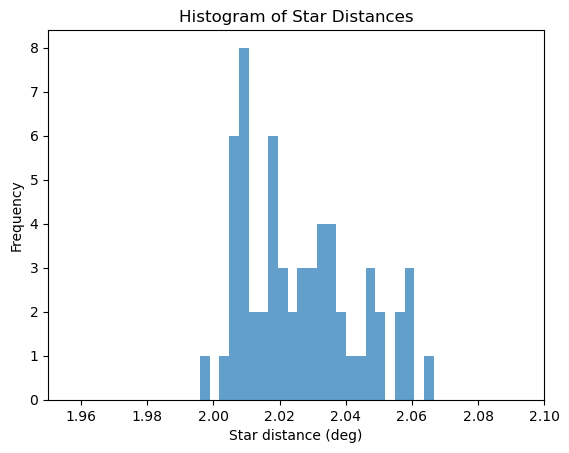

In [32]:
print(dis)
plt.hist(dis, bins=500, alpha=0.7, color='tab:blue')
plt.xlim(1.95, 2.1)
plt.xlabel('Star distance (deg)')
plt.ylabel('Frequency')
plt.title('Histogram of Star Distances')
plt.show()

In [ ]:
suitable_visits=[]
statb = [[],[],[],[],[],[],[],[]]
statc = [[],[],[],[],[],[],[]]
moon_stat=[[],[]]
stat_tel=[[],[],[]]

visit_list=[2026070500875]
visit_list=df_selected['exposure_id']
max_dist = 24* u.deg
client =  EfdClient('usdf_efd')
result_df = cdb_client.query(query_data).to_pandas()

# visits=range(2025051900386,2025051900410)
# prev_dec.clear()
for i,visit in enumerate(visit_list):
    # if visit==2025050600712: continue
    # print('ooooooooooooooooooooooooooooo')
    print(f"Processing visit {visit}...")
    if visit> 2026100000000:
        butler = dafButler.Butler("embargo", collections=["LSSTCam/runs/nightlyValidation","LSSTCam/raw/all"], instrument="LSSTCam")
    else:    
        butler = dafButler.Butler("main", collections=["LSSTCam/raw/all","u/ataranto/general_outputs"], instrument="LSSTCam")

        # visit info
    ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
    dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
    info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
    t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()


    # rot_angle=result_df['rot_ang'][result_df['id']==visit]
    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')

    # bright stars
    try:
        brightest_stars = gu.find_bright_stars(center, max_dist, sorting='Vmag', mag_filter_dict={"Vmag": "<3"}, limit=5)  #decide the ordering of the star, default is decrescent mag
    except Exception as e:
        print(f"Error finding bright stars for visit {visit}: {e}")
        brightest_stars = None
        
    if brightest_stars is not None:
        for i, star in enumerate(brightest_stars):
            starCoord = SkyCoord(ra=star['_RA.icrs'], dec=star['_DE.icrs'], unit=(u.deg, u.deg), frame='icrs')
            staraz = gu.convert_radec_to_altaz("rubin", t, starCoord)
            starDistance = star['Radial_Distance']
            starVMag = star['Vmag']
            star_ha = gu.get_pos_ang(starCoord, center, "rubin", t)
            # print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.2f}, at {starDistance:.2f}°, Clocking angle x-y: {star_ha:.2f}°")

            # print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.2f}, at {starDistance:.2f}°,angle x-y: {starDistance*np.sin(star_ha):.2f}° / {starDistance*np.cos(star_ha):.2f}°")
#REMOVE OR MODIFY IF DEPENDING ON ARTIFACT SEARCH-----------------------
            # if starDistance>20 and starDistance<25:
            statb[0].append(int(star['HIP']))
            statb[1].append(starVMag)
            statb[2].append(starDistance)
            statb[3].append(star_ha.value)
            statb[4].append(staraz.az.deg)
#----------------------------------------------------------------------            
        Dome_azimuth=(await client.select_time_series(
            "lsst.sal.MTDome.azimuth",
            fields=['positionActual'],
            start=Time(t, scale="utc", format="isot")-TimeDelta(3, format='sec'),
            end=Time(t, scale="utc", format="isot")+TimeDelta(3, format='sec')
                     ))
        stat_tel[0].append((Dome_azimuth.max().iloc[0]+Dome_azimuth.min().iloc[0])/2)
        az=result_df['azimuth'][result_df['id']==visit].iloc[0]
        el=result_df['elevation'][result_df['id']==visit].iloc[0]
        stat_tel[1].append(az)
        stat_tel[2].append(el)
        # retrieve moon position
        sat = gu.get_obj_position(t.mjd,'SATURN BARYCENTER')
        satDistance = center.separation(sat).deg
        sat_ha = gu.get_pos_ang(sat, center, "rubin", t)
        jup = gu.get_obj_position(t.mjd,'JUPITER BARYCENTER')
        jupDistance = center.separation(jup).deg
        jup_ha = gu.get_pos_ang(jup, center, "rubin", t)
        moon = gu.get_obj_position(t.mjd,'moon')
        moonDistance = center.separation(moon).deg
        moon_ha = gu.get_pos_ang(moon, center, "rubin", t)
        
        moon_stat[0].append(moonDistance)
        moon_stat[1].append(moon_ha.value)

    

Processing visit 2026010100036...
Processing visit 2026010100037...
Processing visit 2026010100038...
Processing visit 2026010100039...
Processing visit 2026010100052...
Processing visit 2026010100053...
Processing visit 2026010100054...
Processing visit 2026010100098...
Processing visit 2026010100118...
Processing visit 2026010100150...
Processing visit 2026010100151...
Processing visit 2026010100158...
Processing visit 2026010100166...
Processing visit 2026010100167...
Processing visit 2026010100170...
Processing visit 2026010100171...
Processing visit 2026010100185...
Processing visit 2026010100186...
Processing visit 2026010100187...
Processing visit 2026010100209...
Processing visit 2026010100211...
Processing visit 2026010100212...
Processing visit 2026010100218...
Processing visit 2026010100219...
Processing visit 2026010100234...
Processing visit 2026010100239...
Processing visit 2026010100244...
Processing visit 2026010100261...
Processing visit 2026010100263...
Processing vis

CancelledError: 

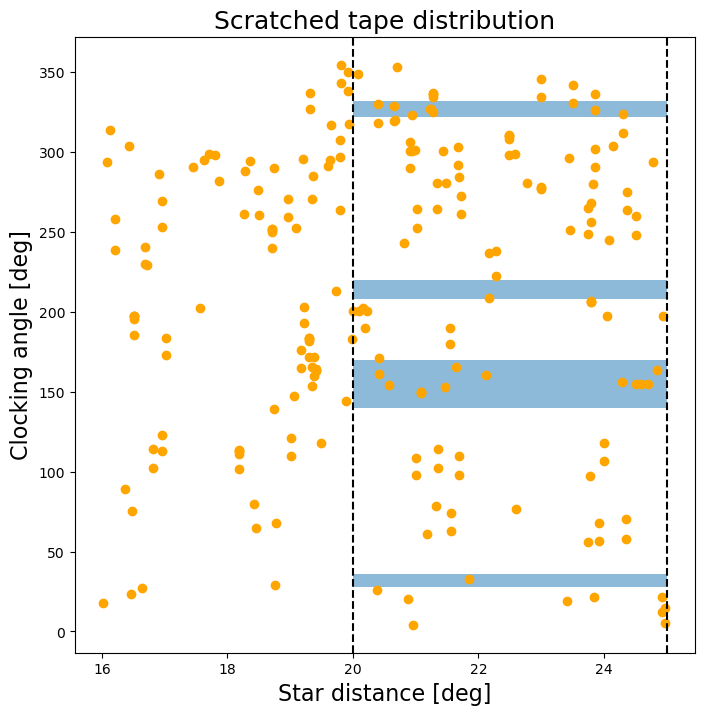

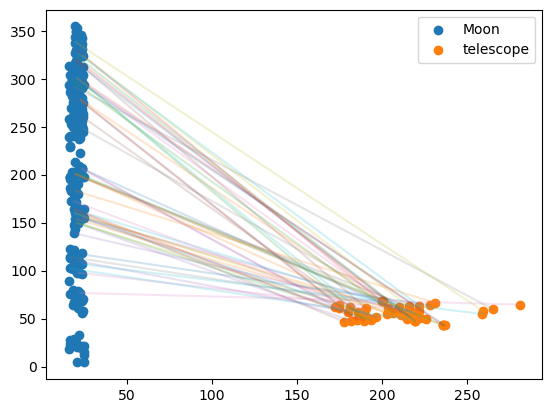

In [6]:

plt.close('all')
fig, axs=plt.subplots(1,1,figsize=(8,8))
sq1=Rectangle(xy=(20,28),width=5,height=8,alpha=0.5)
sq2=Rectangle(xy=(20,140),width=5,height=30,alpha=0.5)
sq3=Rectangle(xy=(20,208),width=5,height=12,alpha=0.5)
sq4=Rectangle(xy=(20,322),width=5,height=10,alpha=0.5)

plt.axvline(x=20,color='k',linestyle='--')
plt.axvline(x=25,color='k',linestyle='--')
axs.add_patch(sq1)
axs.add_patch(sq2)
axs.add_patch(sq3)
axs.add_patch(sq4)
axs.set_xlabel('Star distance [deg]', fontsize=16)
axs.set_ylabel('Clocking angle [deg]', fontsize=16)
axs.set_title('Scratched tape distribution', fontsize=18)

# axs.scatter(statb[2],statb[3])
# moon_clock=np.array(moon_stat[1])*180/np.pi
axs.scatter(statb[2],statb[3],color='orange',label='Moon')
plt.show()

# plt.close('all')
# fig, axs=plt.subplots(1,1,figsize=(8,8))
# sq1=Rectangle(xy=(20,28),width=5,height=8,alpha=0.5)
# sq2=Rectangle(xy=(20,140),width=5,height=30,alpha=0.5)
# sq3=Rectangle(xy=(20,208),width=5,height=12,alpha=0.5)
# sq4=Rectangle(xy=(20,322),width=5,height=10,alpha=0.5)

# plt.axvline(x=20,color='k',linestyle='--')
# plt.axvline(x=25,color='k',linestyle='--')
# axs.add_patch(sq1)
# axs.add_patch(sq2)
# axs.add_patch(sq3)
# axs.add_patch(sq4)
# axs.set_xlabel('Star distance [deg]')
# axs.set_ylabel('Clocking angle [deg]')
# axs.set_title('PILLOW artifacts')

# star_clock=np.array(statb[3])*180/np.pi

# axs.scatter(statb[2],star_clock)
# plt.show()

plt.scatter(statb[2],statb[3], label='Moon')
plt.scatter(stat_tel[1],stat_tel[2],label='telescope')
for i in range(len(moon_stat[2])):
    plt.plot([statb[2][i],stat_tel[1][i]],[statb[3][i],stat_tel[2][i]],alpha=0.2)

plt.legend()


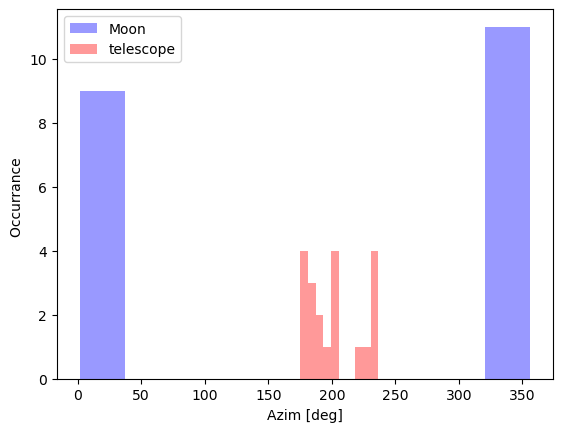

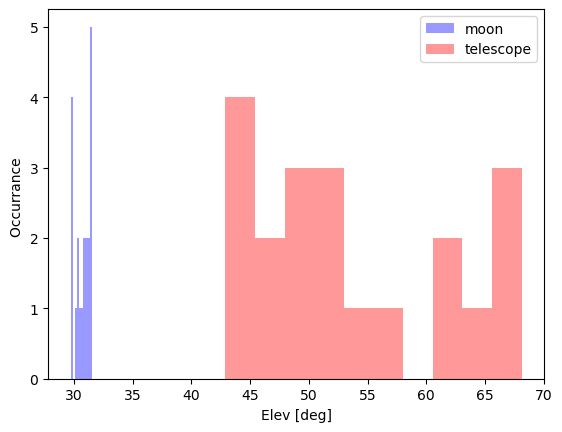

In [5]:
plt.figure()
plt.hist(moon_stat[2], bins=10, label='Moon',color='blue',alpha=0.4)
plt.hist(stat_tel[1], bins=10, label='telescope',color='red',alpha=0.4)

# countsc, binsc, _ = plt.hist(statc[i], bins=30, histtype='step', label='Faint',color='red')

plt.xlabel('Azim [deg]')
plt.ylabel(f"Occurrance ")
plt.legend()

# plt.xlim(-50,50)

plt.show()
plt.figure()
plt.hist(moon_stat[3], bins=10, label='moon',color='blue',alpha=0.4)
plt.hist(stat_tel[2], bins=10, label='telescope',color='red',alpha=0.4)

# countsc, binsc, _ = plt.hist(statc[i], bins=30, histtype='step', label='Faint',color='red')

plt.xlabel('Elev [deg]')
plt.ylabel(f"Occurrance ")
plt.legend()

# plt.xlim(-50,50)

plt.show()



284


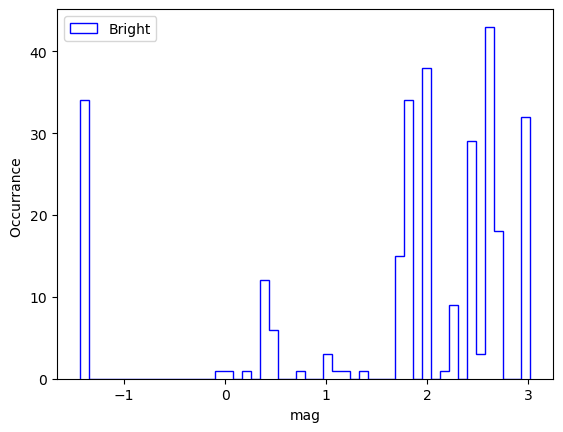

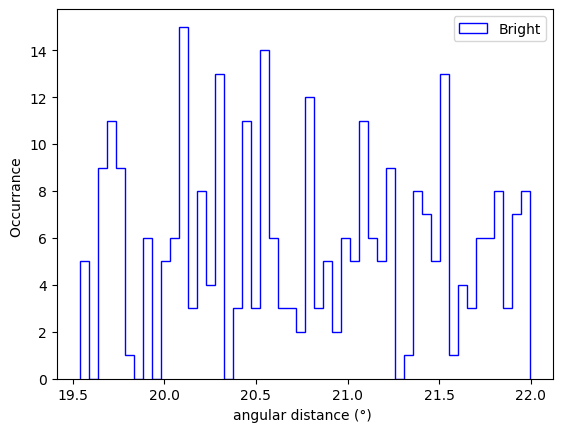

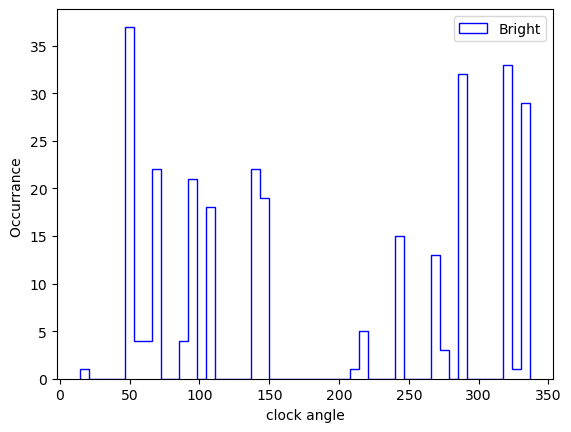

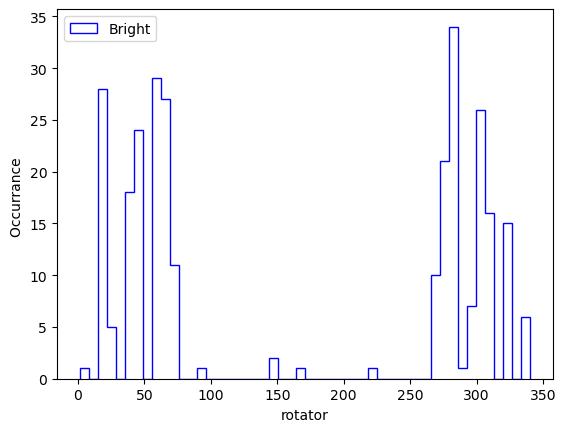

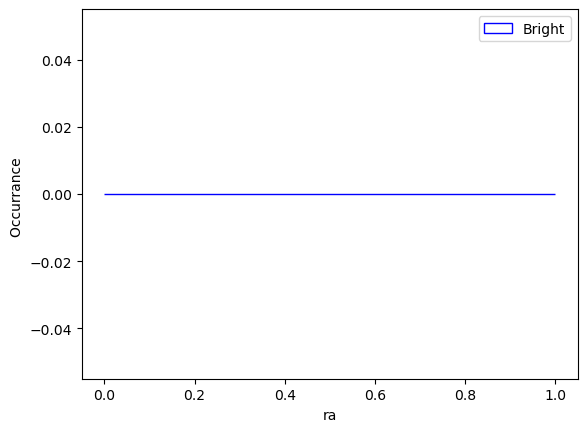

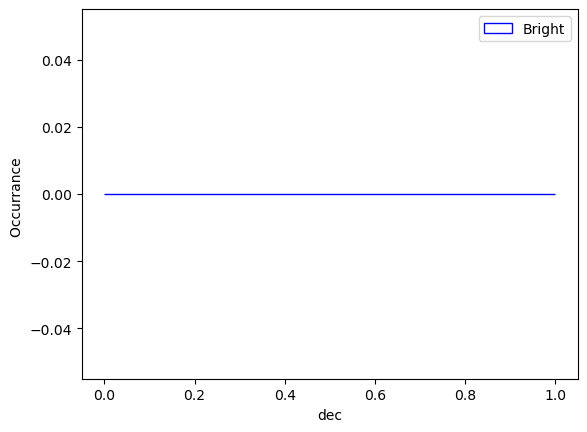

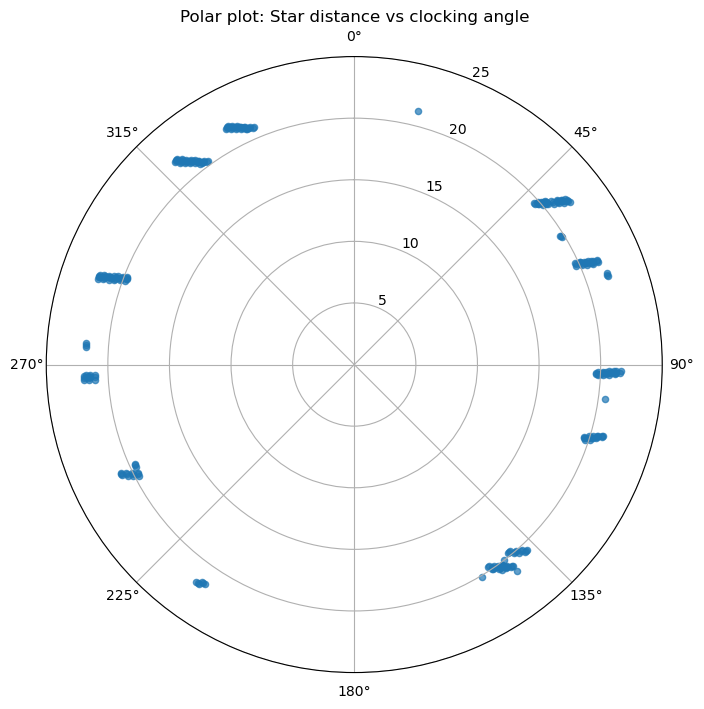

In [7]:
# print(len(stat[0]))
plt.close('all')
lab=['name','mag','angular distance (°) ','clock angle','rotator','ra','dec']
print(len(statb[1]))
for i in range(1,7):
    plt.figure()
    # plt.hist(statc[4], bins=50, histtype='step', label='Close')
    plt.hist(statb[i], bins=50, histtype='step', label='Bright',color='blue')
    # countsc, binsc, _ = plt.hist(statc[i], bins=30, histtype='step', label='Faint',color='red')

    plt.xlabel(lab[i])
    plt.ylabel(f"Occurrance ")
    plt.legend()
    
    # plt.xlim(-50,50)
    
    plt.show()
    

import numpy as np
import matplotlib.pyplot as plt

r = np.asarray(statb[2], dtype=float)          # radius
theta = np.deg2rad(np.asarray(statb[3], dtype=float))  # angle in rad

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, projection='polar')
ax.scatter(theta, r, s=20, alpha=0.7, color='tab:blue')
ax.set_ylim(0, 25)
ax.set_title("Polar plot: Star distance vs clocking angle")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.grid(True)
plt.show()
    # max_bin_indexb = countsb.argmax()
    # max_bin_indexc = countsc.argmax()
    # # print(f"Bin with highest occurrence: {binsb[max_bin_indexb]} - {binsb[max_bin_indexb+1]}, count: {int(countsb[max_bin_indexb])}")
    
    # # Print the values in stat[0] that fall inside this bin range
    # bin_minb = binsb[max_bin_indexb]
    # bin_maxb = binsb[max_bin_indexb + 1]
    # values_in_binb = [x for x in statb[i] if bin_minb <= x < bin_maxb]
    # print("Values in this bin:", values_in_binb)
# plt.plot(stat[1], stat[2], 'o', markersize=2, label='Vmag')
# plt.xlim(0.5,2)




In [ ]:
import numpy as np
from matplotlib.patches import Circle
import matplotlib.pyplot as plt
# data = np.array(statb)
# print(data[5:7])
xy = np.round(statb[5:7],2)              # (x, y) coordinate
measurements = statb[:5]     # measurements
xy_keys = np.array(['{}_{}'.format(x, y) for x, y in xy.T])
# print(xy_keys) # Count occurrences
unique_keys, counts = np.unique(xy_keys, return_counts=True)

# Map keys to weights (1 / count)
key_to_weight = dict(zip(unique_keys, 1 / counts))
weights = np.array([key_to_weight[k] for k in xy_keys])

print("Measurements:", len(measurements[0]))
print("Weights:", len(weights))
# Use all unique HIP numbers in measurements[0]
hip_numbers = np.unique(statb[0])
print((", ".join(str(int(hip)) for hip in hip_numbers)))

# Query Hipparcos catalog for all these HIP numbers to get their RA/DEC
# We'll use Vizier and the "I/239/hip_main" catalog
result = Vizier.query_constraints(catalog="I/239/hip_main", HIP=", ".join(str(int(hip)) for hip in hip_numbers))
if len(result) == 0:
    raise RuntimeError("No stars found in Hipparcos catalog for the given HIP numbers.")
hip_table = result[0]

# Build a dict: HIP -> (RA, DEC)
hip_to_coord = {row['HIP']: (row['_RA.icrs'], row['_DE.icrs']) for row in hip_table}

# Now, for each unique HIP, add a circle and a marker



In [ ]:
plt.close('all')

for m in range(1, 6):
    fig, axs = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [1, 2]})

    # Top: weighted histogram
    # Prepare indices for the three groups
    idx0 = np.arange(0, len(measurements[m]), 3)
    idx1 = np.arange(1, len(measurements[m]), 3)
    idx2 = np.arange(2, len(measurements[m]), 3)

    axs[0].hist(np.array(measurements[m])[idx0], bins=50, weights=weights[idx0], edgecolor='black', alpha=0.7, label='1st Brightest star')
    axs[0].hist(np.array(measurements[m])[idx1], bins=50, weights=weights[idx1], edgecolor='red', alpha=0.7, label='2nd Brightest star')
    axs[0].hist(np.array(measurements[m])[idx2], bins=50, weights=weights[idx2], edgecolor='green', alpha=0.7, label='3th Brightest star')
    axs[0].legend()
    axs[0].set_xlabel(lab[m])
    axs[0].set_ylabel("Weighted Count")
    axs[0].set_title(f"Weighted Histogram (Normalized by (RA-DEC) Sampling Frequency) - {lab[m]}")
    axs[0].grid(True)

    # Bottom: scatter plot
    # Add circles and markers for all unique HIPs
    avoid=[ 57632,  59803, 60718, 61359, 61932,   68702,  
             78401, 78820,  81377, 85927, 86032, 109268]
    avoid=[]    # avoid=[ 54872,57632,   60718, 61359, 61932,61941, 67927, 68702, 72622,74785,77070,
    #         78401, 78820,  81377, 82273, 82396,  85927,  86032]
    for hip in hip_numbers:
        hip = int(hip)
        if  hip in avoid:
            continue
        if hip in hip_to_coord:
            ra, dec = hip_to_coord[hip]
            circle_in = Circle((ra, dec), 19, color='gray', fill=False, alpha=0.3)
            circle_out = Circle((ra, dec), 24, color='gray', fill=False, alpha=0.3)
            axs[1].add_patch(circle_in)
            axs[1].add_patch(circle_out)
            axs[1].scatter(ra, dec, color='black', marker='*', s=70, label='Bright off-axis star')
            # Annotate HIP number and Vmag
            vmag = hip_table[hip_table['HIP'] == hip]['Vmag'][0] if hip in hip_table['HIP'] else None
            label = f"{hip}"
            if vmag is not None:
                label += f" ({vmag:.2f})"
            axs[1].annotate(label, (ra, dec), textcoords="offset points", xytext=(5, 5), ha='center', fontsize=8, color='black')

    # Scatter the positions colored by measurement
    
    reshaped = np.asarray(measurements[1]).reshape(-1, 3)
    min_values = reshaped.min(axis=1)
    color_mag = np.repeat(min_values, 3)
    sc = axs[1].scatter(xy[0], xy[1], alpha=0.99,label='Exposures with tape')
    axs[1].set_xlabel("RA")
    axs[1].set_ylabel("DEC")
    axs[1].set_title(f"RA-DEC Scatter")
   
    axs[1].set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.legend()
    
    plt.show()

In [ ]:
#MOON HIST  
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(moon_stat[0], bins=30, color='skyblue', edgecolor='black')
plt.xlabel("Moon Distance (deg)")
plt.ylabel("Count")
plt.title("Histogram of Moon Distance")

plt.subplot(1, 2, 2)
plt.hist(moon_stat[1], bins=30, color='orange', edgecolor='black')
plt.xlabel("Moon Clocking Angle (deg)")
plt.ylabel("Count")
plt.title("Histogram of Moon Clocking Angle")

plt.tight_layout()
plt.show()

In [ ]:
plt.scatter(statb[1],statb[2], color='green' )
plt.xlabel('Magnitude')
plt.ylabel('Off-Axis Distance ° ')
plt.axhline(19)
plt.axhline(24)

In [ ]:
print(df_selected['exposure_id'].iloc[-5])

In [ ]:
print(len(statb[2])/113)